# Customer Segmentation Study

**CodeNova Data Science · Task 4**

This executed notebook builds Recency, Frequency, and Monetary features from an included, reproducible fictional transaction sample; log-transforms and scales the features; evaluates K-Means cluster counts using the Elbow and Silhouette methods; and explains the resulting behavioral personas.

> The assignment permits public or synthetic data. Every customer and transaction in this study is fictional.

## 1. Generate and inspect the sample

The fixed-seed generator produces transactions from five latent behavior patterns for method demonstration. These patterns are synthetic design choices, not observed market segments.

In [1]:
from src.generate_transactions import generate
generate()
import pandas as pd
transactions = pd.read_csv("data/transactions.csv", parse_dates=["order_date"])
print(f"Rows: {len(transactions):,} | customers: {transactions.customer_id.nunique():,} | date range: {transactions.order_date.min().date()} to {transactions.order_date.max().date()}")
transactions.head()

Wrote 10,156 synthetic transactions for 600 fictional customers to C:\Users\buddo\Documents\Codex\2026-10-27\b\outputs\customer-segmentation-study\data\transactions.csv


Rows: 10,156 | customers: 600 | date range: 2024-01-06 to 2025-12-30


,customer_id,order_id,order_date,sales,units,category
0,C0001,C0001-O001,2024-12-08,83.71,2,Office Supplies
1,C0001,C0001-O002,2024-12-09,109.30,2,Furniture
2,C0001,C0001-O003,2025-01-06,122.56,1,Technology
3,C0001,C0001-O004,2025-01-09,106.71,2,Technology
4,C0001,C0001-O005,2025-01-14,146.99,1,Furniture


## 2. Construct RFM features

Recency is measured in days from the reference date (one day after the final transaction), frequency counts distinct orders, and monetary value sums line-item sales. A log transform reduces skew before standardization.

In [2]:
from src.segment_customers import build_rfm
rfm, reference_date = build_rfm(transactions)
print(f"Reference date: {reference_date.date()} | customers: {len(rfm):,}")
rfm.describe().round(2)

Reference date: 2025-12-31 | customers: 600


,recency,frequency,monetary
count,600.00,600.00,600.00
mean,179.25,16.93,688.84
std,153.92,14.51,471.92
min,1.00,1.00,26.42
25%,53.00,6.00,197.58
50%,123.00,11.00,729.82
75%,275.00,27.00,1089.58
max,687.00,70.00,2058.74


## 3. Select cluster count and fit K-Means

For candidate k values from 2 through 7, K-Means uses 20 initializations and fixed seed 42. The selected k is the maximum mean Silhouette score in that tested range; the Elbow curve is reviewed alongside it. Scores support a choice but do not prove that a segment is useful.

In [3]:
from src.segment_customers import run
rfm_segmented, silhouette_by_k, inertia_by_k, selected_k, pca, scaled_features = run()
print(f"Chosen k={selected_k}; silhouette={silhouette_by_k[selected_k]:.3f}")

customers=600 transactions=10156 selected_k=4 silhouette=0.5472
silhouette_by_k=2:0.544, 3:0.544, 4:0.547, 5:0.458, 6:0.456, 7:0.464
                       customers  median_recency_days  median_orders  median_spend
persona                                                                           
Occasional Customers         228                206.0            5.0       167.465
Champions                    162                 52.0           38.0      1096.950
At-Risk High Value           116                420.5           13.0       767.875
Champions (Segment 3)         94                 43.5           12.5      1117.035
explained_variance_ratio=[np.float64(0.7445), np.float64(0.2054)]
Chosen k=4; silhouette=0.547


## 4. Interpret personas and inspect projections

Persona labels are assigned from each segment's median RFM behavior relative to sample-wide medians. PCA is used only for a two-dimensional view; the model is fitted in all three scaled RFM features.

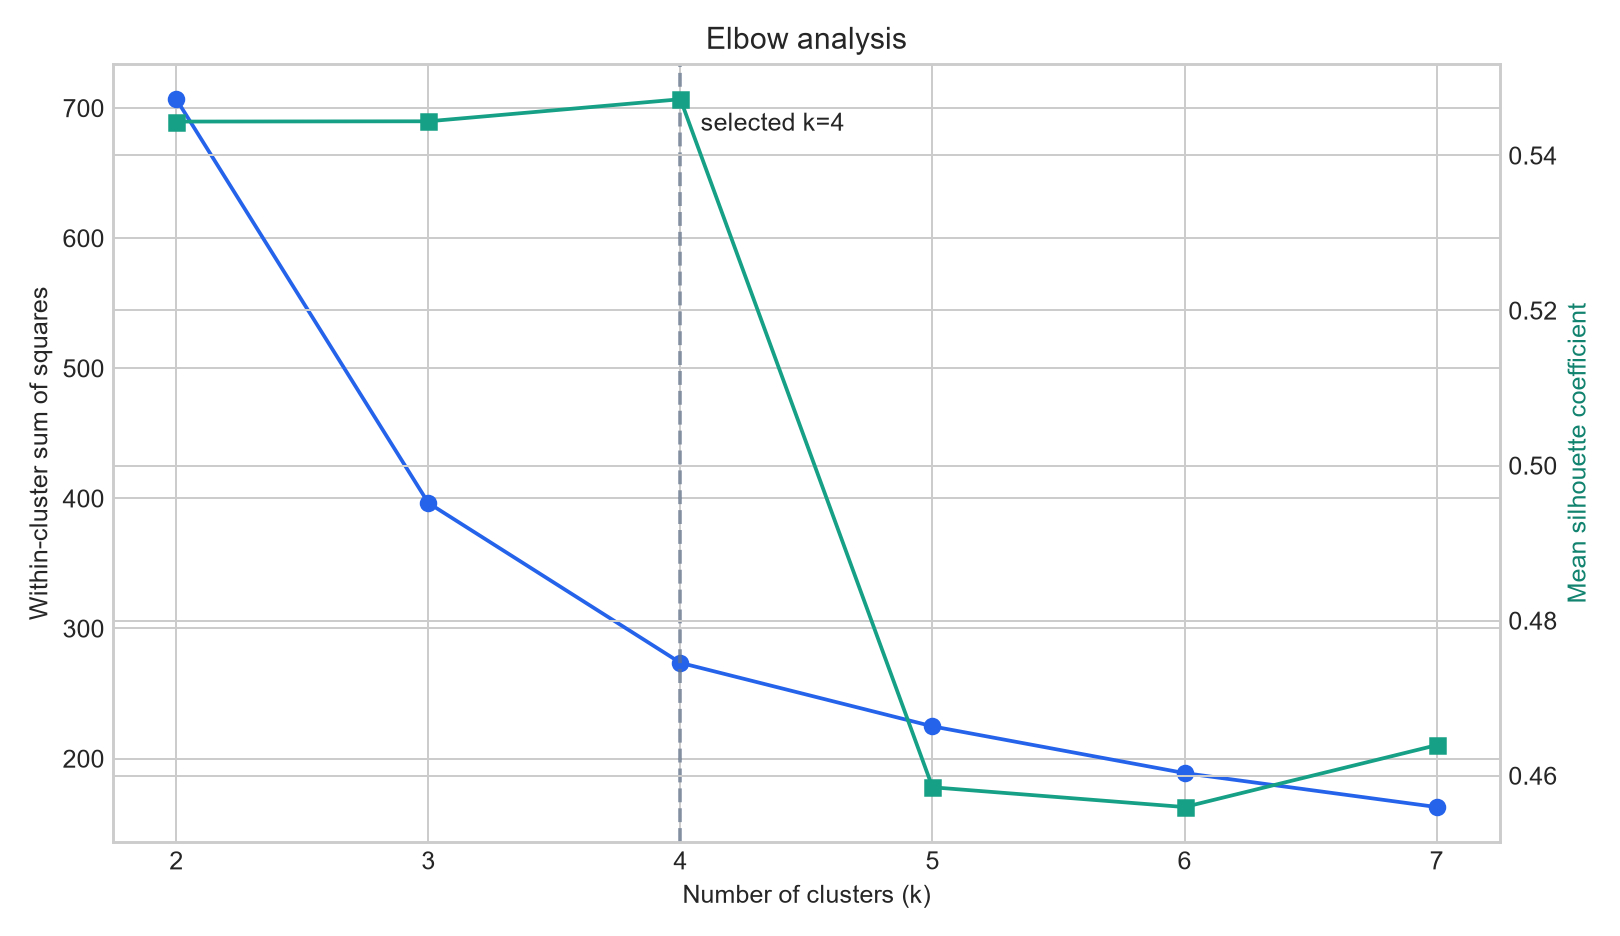

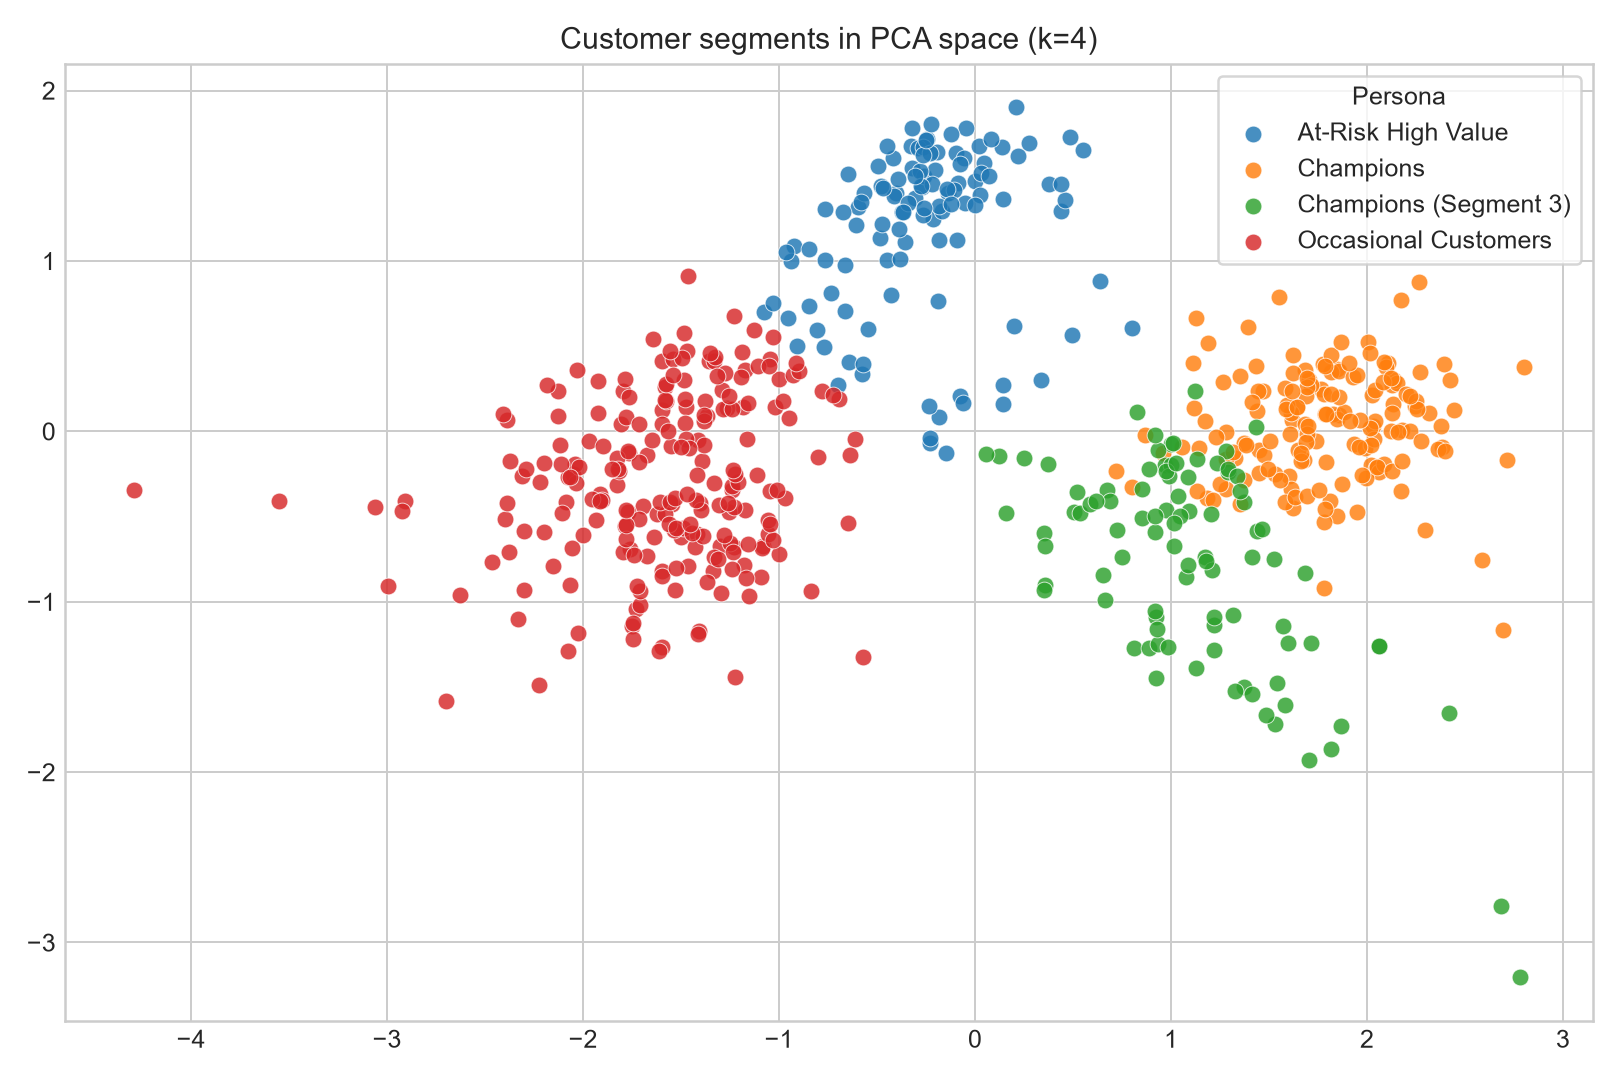

,customers,median_recency_days,median_orders,median_spend
persona,,,,
Occasional Customers,228,206.0,5.0,167.5
Champions,162,52.0,38.0,1097.0
At-Risk High Value,116,420.5,13.0,767.9
Champions (Segment 3),94,43.5,12.5,1117.0


In [4]:
from IPython.display import display, Image
display(Image(filename="figures/cluster_selection.png"))
display(Image(filename="figures/pca_segments.png"))
rfm_segmented.groupby("persona").agg(customers=("recency","size"), median_recency_days=("recency","median"), median_orders=("frequency","median"), median_spend=("monetary","median")).round(1).sort_values("customers", ascending=False)

## Findings and limits

See `reports/persona_summary.md` for the compact persona descriptions and suggested marketing experiments. The dataset is synthetic and the generator intentionally varies behavioral patterns. Results should not be treated as real customer evidence. K-Means favors compact Euclidean groups, depends on scaling and initialization, and assigns every customer to a group. Real deployment requires privacy, consent, fairness, stability, and business validation.